# Análisis de cosechas: censura, ciclo y el problema de identificación edad-cosecha-periodo

**Perfil:** Riesgo de crédito (productos)  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

¿Qué cosecha de originación es realmente peor? Comparar el incumplimiento acumulado "a la fecha" engaña porque las cosechas jóvenes se han observado menos tiempo; y aun comparando a igual edad, una recesión que cae sobre ciertas cosechas se confunde con mala calidad de originación.

## Recorrido

1. Datos sintéticos de 24 cosechas con calidad propia, una curva de maduración y una recesión calendario.
2. **Versión 1:** comparar el incumplimiento acumulado a la fecha (ingenua).
3. **Versión 2:** comparar a igual edad y proyectar cosechas incompletas por *chain-ladder*.
4. **Diagnóstico:** el mapa edad × calendario revela la recesión como una franja vertical.
5. **Versión 3:** modelo de riesgo discreto edad + cosecha + periodo, con su problema de identificación.
6. Proyección, robustez, pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
import statsmodels.api as sm
from scipy.stats import spearmanr

## 2. El mundo simulado

Para una cosecha $v$ (mes de originación) y una edad $a$ (meses desde el origen), el calendario es $t=v+a$. El riesgo instantáneo de incumplir es

$$h(v,a)=h_0\;s(a)\;q_v\;m(t),$$

con $s(a)$ una **curva de maduración** (sube hasta el mes 8 y luego decae), $q_v$ la **calidad de la cosecha** y $m(t)$ un **choque macro** (una recesión centrada en el mes 17). Tres cosechas consecutivas (8 a 10) tienen estándares laxos: calidad 45 % peor. La observación termina en el mes 30, de modo que las cosechas recientes tienen pocas edades observadas (**censura por la derecha**).

In [2]:
V, T_OBS, N = 24, 30, 8000
H0 = 0.0045
sazon = lambda a: (a / 8) * np.exp(1 - a / 8)
macro = lambda t: 1 + 0.6 * np.exp(-0.5 * ((t - 17) / 2.5) ** 2)

rng = np.random.default_rng(SEED)
calidad = rng.lognormal(0, 0.10, V)
calidad[8:11] *= 1.45                                   # estandares laxos en las cosechas 8-10
hazard = lambda v, a: H0 * sazon(a) * calidad[v] * macro(v + a)

filas = []
for v in range(V):
    en_riesgo = N
    for a in range(1, T_OBS - v + 1):                   # solo hasta el mes 30 (censura)
        d = rng.binomial(en_riesgo, hazard(v, a))
        filas.append((v, a, v + a, en_riesgo, d))
        en_riesgo -= d
celdas = pd.DataFrame(filas, columns=["v", "a", "t", "riesgo", "d"])
celdas["h_obs"] = celdas["d"] / celdas["riesgo"]
print(celdas.shape, "| defaults totales:", int(celdas["d"].sum()))
celdas.groupby("v")["a"].max().rename("edades_observadas").to_frame().T

(444, 6) | defaults totales: 14414


v,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
edades_observadas,30,29,28,27,26,25,24,23,22,21,...,16,15,14,13,12,11,10,9,8,7


## 3. Versión 1: incumplimiento acumulado a la fecha

La comparación más directa: para cada cosecha, el total de incumplimientos dividido por los créditos originados.

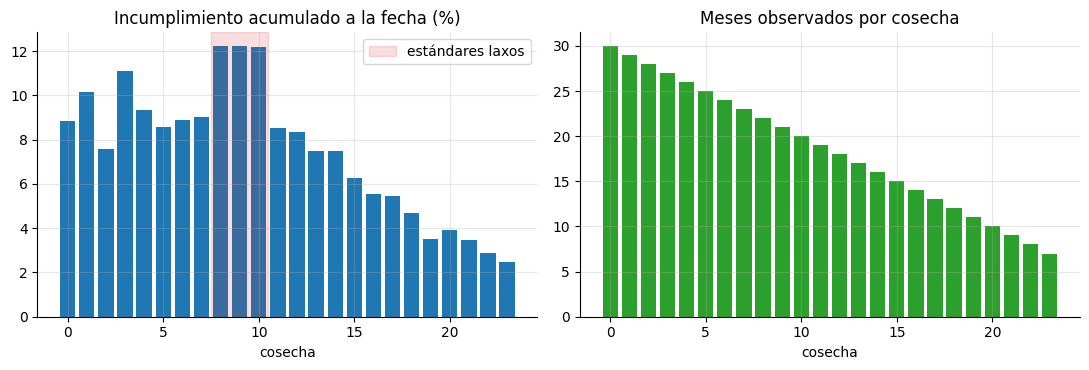

Correlacion de rangos entre el 'acumulado a la fecha' y la calidad VERDADERA de la cosecha: +0.52
Correlacion de rangos entre el 'acumulado a la fecha' y los meses observados: +0.83


In [3]:
v1 = celdas.groupby("v")["d"].sum() / N
edades_obs = celdas.groupby("v")["a"].max()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(v1.index, v1.values * 100, color="C0"); ax[0].set_title("Incumplimiento acumulado a la fecha (%)")
ax[0].set_xlabel("cosecha"); ax[0].axvspan(7.5, 10.5, color="C3", alpha=0.15, label="estándares laxos")
ax[0].legend()
ax[1].bar(edades_obs.index, edades_obs.values, color="C2"); ax[1].set_title("Meses observados por cosecha"); ax[1].set_xlabel("cosecha")
plt.tight_layout(); plt.show()
rho_v1 = spearmanr(v1.values, calidad)[0]
print(f"Correlacion de rangos entre el 'acumulado a la fecha' y la calidad VERDADERA de la cosecha: {rho_v1:+.2f}")
print(f"Correlacion de rangos entre el 'acumulado a la fecha' y los meses observados: {spearmanr(v1.values, edades_obs.values)[0]:+.2f}")

**Qué muestra.** La métrica queda dominada por **cuánto tiempo se ha observado** cada cosecha, no por su calidad: las cosechas antiguas parecen "peores" simplemente porque tuvieron más tiempo para incumplir. Se necesita comparar **a igual edad**.

## 4. Versión 2: igual edad y proyección

### 4.1 Comparar a una edad común

El incumplimiento acumulado a la edad $a^*$ es $1-\prod_{a\le a^*}(1-d_{v,a}/r_{v,a})$. Se compara a 6 meses (observado en todas las cosechas) y a 12 meses (observado en las 19 primeras).

In [4]:
def acumulado(v, hasta):
    c = celdas[(celdas["v"] == v) & (celdas["a"] <= hasta)]
    return 1 - np.prod(1 - c["h_obs"].to_numpy()) if c["a"].max() >= hasta else np.nan

acum6 = pd.Series({v: acumulado(v, 6) for v in range(V)})
acum12 = pd.Series({v: acumulado(v, 12) for v in range(V)})
rho6 = spearmanr(acum6.values, calidad)[0]
ok12 = acum12.notna().to_numpy()
rho12 = spearmanr(acum12[ok12].values, calidad[ok12])[0]
print(f"Spearman con la calidad verdadera: a 6 meses {rho6:+.2f} | a 12 meses {rho12:+.2f} | a la fecha (v1) {rho_v1:+.2f}")

Spearman con la calidad verdadera: a 6 meses +0.56 | a 12 meses +0.75 | a la fecha (v1) +0.52


Regresion: log(incumplimiento a 6 meses) ~ log(calidad verdadera) + exposicion macro de esos 6 meses
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -3.9675      0.020   -201.438      0.000      -4.008      -3.927
log_calidad       1.0587      0.098     10.775      0.000       0.854       1.263
expo_macro_6m     1.2014      0.102     11.788      0.000       0.989       1.413
R2 = 0.93. Si el modelo es correcto, ambos coeficientes deberian rondar 1 (el riesgo es multiplicativo).
Lectura: la exposicion macro de la cosecha tiene coeficiente +1.20 (p=1.0e-10): a igual edad, una cosecha que vive la recesion incumple mas sin ser peor.


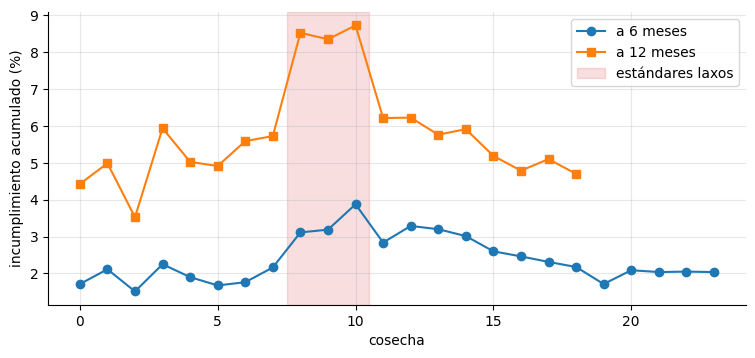

In [5]:
expo6 = pd.Series({v: np.mean(np.log(macro(v + np.arange(1, 7)))) for v in range(V)})
dfx = pd.DataFrame({"y": np.log(acum6.values), "log_calidad": np.log(calidad), "expo_macro_6m": expo6.values})
ols = sm.OLS(dfx["y"], sm.add_constant(dfx[["log_calidad", "expo_macro_6m"]])).fit()
print("Regresion: log(incumplimiento a 6 meses) ~ log(calidad verdadera) + exposicion macro de esos 6 meses")
print(ols.summary().tables[1])
print(f"R2 = {ols.rsquared:.2f}. Si el modelo es correcto, ambos coeficientes deberian rondar 1 (el riesgo es multiplicativo).")
print(f"Lectura: la exposicion macro de la cosecha tiene coeficiente {ols.params['expo_macro_6m']:+.2f} (p={ols.pvalues['expo_macro_6m']:.1e}): a igual edad, una cosecha que vive la recesion incumple mas sin ser peor.")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(acum6.index, acum6 * 100, "o-", label="a 6 meses")
ax.plot(acum12.index, acum12 * 100, "s-", label="a 12 meses")
ax.axvspan(7.5, 10.5, color="C3", alpha=0.15, label="estándares laxos")
ax.set_xlabel("cosecha"); ax.set_ylabel("incumplimiento acumulado (%)"); ax.legend(); plt.show()

Comparar a igual edad corrige la censura, pero **la mejora del ranking es pequeña**. La razón está en la regresión anterior: además de la calidad, el nivel de incumplimiento a una edad dada depende de **cuánta recesión le tocó vivir** a esa cosecha en esos meses, y esa parte no tiene que ver con su calidad de originación.

### 4.2 Diagnóstico: el mapa edad × calendario

Si no hubiera choque macro, el riesgo observado dividido por la curva de maduración promedio sería casi plano. Se grafica esa razón con el **calendario en el eje horizontal**: un efecto de periodo aparece como una **franja vertical**; uno de cosecha, como una **diagonal**.

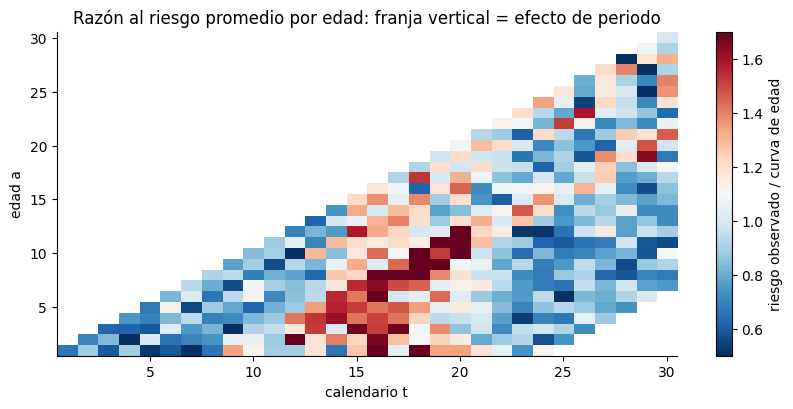

Razon observada/esperada por calendario: minimo 0.67 (t=1), maximo 1.44 (t=16)
El maximo cae en el calendario 16; el choque verdadero tiene su pico en t=17.


In [6]:
h_edad = celdas.groupby("a").apply(lambda g: g["d"].sum() / g["riesgo"].sum())          # curva de maduracion agrupada
celdas["razon"] = celdas["h_obs"] / celdas["a"].map(h_edad)
mapa = celdas.pivot_table(index="a", columns="t", values="razon", aggfunc="mean")
fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(mapa.values, aspect="auto", origin="lower", cmap="RdBu_r", vmin=0.5, vmax=1.7,
               extent=[mapa.columns.min() - .5, mapa.columns.max() + .5, mapa.index.min() - .5, mapa.index.max() + .5])
ax.set_xlabel("calendario t"); ax.set_ylabel("edad a"); ax.grid(False); plt.colorbar(im, label="riesgo observado / curva de edad")
plt.title("Razón al riesgo promedio por edad: franja vertical = efecto de periodo"); plt.show()
por_t = celdas.groupby("t").apply(lambda g: g["d"].sum() / (g["riesgo"] * g["a"].map(h_edad)).sum())
print(f"Razon observada/esperada por calendario: minimo {por_t.min():.2f} (t={por_t.idxmin()}), maximo {por_t.max():.2f} (t={por_t.idxmax()})")
print(f"El maximo cae en el calendario {por_t.idxmax()}; el choque verdadero tiene su pico en t=17.")

### 4.3 Proyección de cosechas incompletas (*chain-ladder* por riesgo)

Para estimar el incumplimiento a 18 meses de las cosechas que aún no lo alcanzan, se completa su curva con el **riesgo promedio por edad** $\hat h(a)$ y, opcionalmente, un factor de cosecha $\hat q_v=\sum d/\sum \hat h(a)\,r$.

In [7]:
EDAD_OBJ = 18
def verdad_acum(v, hasta=EDAD_OBJ):
    return 1 - np.prod([1 - H0 * sazon(a) * calidad[v] * (macro(v + a) if v + a <= T_OBS else 1.0) for a in range(1, hasta + 1)])
    # nota: despues del mes 30 se supone el choque ya disipado (m=1)

def proyectar(v, h_a, con_factor):
    c = celdas[celdas["v"] == v]
    ultima = c["a"].max()
    S = np.prod(1 - c["h_obs"].to_numpy())
    q = c["d"].sum() / (c["riesgo"] * c["a"].map(h_a)).sum() if con_factor else 1.0
    for a in range(ultima + 1, EDAD_OBJ + 1):
        S *= 1 - min(h_a[a] * q, 0.99)
    return 1 - S if ultima < EDAD_OBJ else acumulado(v, EDAD_OBJ)

incompletas = [v for v in range(V) if edades_obs[v] < EDAD_OBJ]
res_proy = pd.DataFrame({"v": incompletas})
res_proy["verdad"] = [verdad_acum(v) for v in incompletas]
res_proy["v2_sin_factor"] = [proyectar(v, h_edad, False) for v in incompletas]
res_proy["v2_con_factor"] = [proyectar(v, h_edad, True) for v in incompletas]
res_proy = res_proy.set_index("v")
for c_ in ("v2_sin_factor", "v2_con_factor"):
    res_proy[f"err_{c_}_%"] = (res_proy[c_] / res_proy["verdad"] - 1) * 100
res_proy.round(4)

,verdad,v2_sin_factor,v2_con_factor,err_v2_sin_factor_%,err_v2_con_factor_%
v,,,,,
13,0.0744,0.0781,0.0780,4.9254,4.8206
14,0.0744,0.0820,0.0822,10.1992,10.4642
15,0.0671,0.0735,0.0724,9.5848,7.9641
16,0.0665,0.0708,0.0685,6.5105,3.0525
17,0.0710,0.0743,0.0724,4.7642,1.9748
18,0.0650,0.0718,0.0679,10.4420,4.4495
19,0.0567,0.0652,0.0559,14.9369,-1.5039
20,0.0613,0.0742,0.0694,21.0888,13.2117
21,0.0681,0.0749,0.0693,10.0395,1.8431


## 5. Versión 3: modelo de riesgo discreto con edad, cosecha y periodo

Se ajusta un modelo logístico de riesgo discreto sobre las celdas (cosecha × edad), con **tres conjuntos de efectos**:

$$\operatorname{logit} h(v,a,t)=\alpha_a+\beta_v+\gamma_t.$$

**El problema de identificación.** Como $t=v+a$, una tendencia lineal se puede mover libremente entre $\alpha$, $\beta$ y $\gamma$ sin cambiar el ajuste: *solo las curvaturas están identificadas*. Aquí se fija una convención: los efectos de periodo se **ortogonalizan** respecto de una constante y una tendencia, de modo que la tendencia lineal queda asignada a edad y cosecha. Al comparar con la verdad, también se quita la tendencia lineal de los efectos de cosecha.

In [8]:
def disenos(cel, con_periodo):
    Xa = pd.get_dummies(cel["a"], prefix="a", drop_first=True).astype(float)
    Xv = pd.get_dummies(cel["v"], prefix="v", drop_first=True).astype(float)
    partes = [pd.Series(1.0, index=cel.index, name="const"), Xa, Xv]
    if con_periodo:
        Xt = pd.get_dummies(cel["t"], prefix="t").astype(float)
        Z = np.column_stack([np.ones(len(cel)), cel["t"].to_numpy()])
        Xt_res = pd.DataFrame(Xt.to_numpy() - Z @ np.linalg.lstsq(Z, Xt.to_numpy(), rcond=None)[0], index=cel.index, columns=Xt.columns)
        partes.append(Xt_res)
    return pd.concat(partes, axis=1)


def ajustar(con_periodo):
    X = disenos(celdas, con_periodo)
    y = np.column_stack([celdas["d"], celdas["riesgo"] - celdas["d"]])
    m = sm.GLM(y, X.to_numpy(), family=sm.families.Binomial()).fit()
    return m, X

mA, XA = ajustar(False)
mB, XB = ajustar(True)
print(f"Deviance modelo A (edad + cosecha):             {mA.deviance:,.1f} ({XA.shape[1]} parametros)")
print(f"Deviance modelo B (edad + cosecha + periodo):   {mB.deviance:,.1f} ({XB.shape[1]} parametros)")
print(f"Grados de libertad residuales: A={mA.df_resid}, B={mB.df_resid}  (deviance esperada ~ grados de libertad si el modelo es correcto)")
print(f"Lectura: deviance/gl = {mA.deviance / mA.df_resid:.2f} sin periodo y {mB.deviance / mB.df_resid:.2f} con periodo. Un valor cercano a 1 indica buen ajuste; sin periodo hay una estructura sin explicar.")

Deviance modelo A (edad + cosecha):             767.3 (53 parametros)
Deviance modelo B (edad + cosecha + periodo):   344.2 (83 parametros)
Grados de libertad residuales: A=391, B=363  (deviance esperada ~ grados de libertad si el modelo es correcto)
Lectura: deviance/gl = 1.96 sin periodo y 0.95 con periodo. Un valor cercano a 1 indica buen ajuste; sin periodo hay una estructura sin explicar.


In [9]:
def efectos(m, X):
    coef = pd.Series(m.params, index=X.columns)
    ef_v = pd.Series([0.0] + [coef[f"v_{k}"] for k in range(1, V)], index=range(V))
    ef_t = None
    cols_t = [c for c in X.columns if c.startswith("t_")]
    if cols_t:
        ef_t = (X[cols_t] @ coef[cols_t]).groupby(celdas["t"]).first()
    return coef, ef_v, ef_t

def sin_tendencia(x):
    x = np.asarray(x, float); k = np.arange(len(x))
    A = np.column_stack([np.ones(len(x)), k])
    return x - A @ np.linalg.lstsq(A, x, rcond=None)[0]

coefA, ef_vA, _ = efectos(mA, XA)
coefB, ef_vB, ef_tB = efectos(mB, XB)
verdad_v = np.log(calidad) - np.log(calidad[0])
res_ident = pd.DataFrame({
    "modelo": ["A: edad + cosecha", "B: edad + cosecha + periodo"],
    "correlacion_con_calidad_verdadera": [np.corrcoef(sin_tendencia(ef_vA), sin_tendencia(verdad_v))[0, 1],
                                          np.corrcoef(sin_tendencia(ef_vB), sin_tendencia(verdad_v))[0, 1]],
    "RMSE_log_calidad": [np.sqrt(np.mean((sin_tendencia(ef_vA) - sin_tendencia(verdad_v)) ** 2)),
                         np.sqrt(np.mean((sin_tendencia(ef_vB) - sin_tendencia(verdad_v)) ** 2))],
}).set_index("modelo")
res_ident

,correlacion_con_calidad_verdadera,RMSE_log_calidad
modelo,,
A: edad + cosecha,0.9383,0.0639
B: edad + cosecha + periodo,0.9560,0.0430


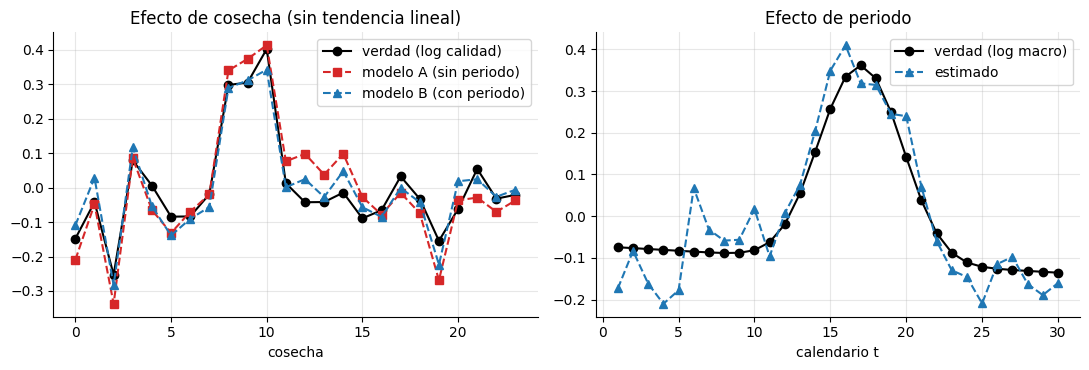

Lectura:
  El modelo B recupera el efecto de periodo con correlacion 0.94 respecto del choque verdadero.
  El RMSE de los efectos de cosecha cae de 0.064 (sin periodo) a 0.043 (con periodo).


In [10]:
t_idx = ef_tB.index.to_numpy()
verdad_t = np.log(macro(t_idx))
corr_t = np.corrcoef(sin_tendencia(ef_tB.values), sin_tendencia(verdad_t))[0, 1]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(range(V), sin_tendencia(verdad_v), "k-o", label="verdad (log calidad)")
ax[0].plot(range(V), sin_tendencia(ef_vA), "C3--s", label="modelo A (sin periodo)")
ax[0].plot(range(V), sin_tendencia(ef_vB), "C0--^", label="modelo B (con periodo)")
ax[0].set_title("Efecto de cosecha (sin tendencia lineal)"); ax[0].set_xlabel("cosecha"); ax[0].legend()
ax[1].plot(t_idx, sin_tendencia(verdad_t), "k-o", label="verdad (log macro)")
ax[1].plot(t_idx, sin_tendencia(ef_tB.values), "C0--^", label="estimado")
ax[1].set_title("Efecto de periodo"); ax[1].set_xlabel("calendario t"); ax[1].legend()
plt.tight_layout(); plt.show()
print("Lectura:")
print(f"  El modelo B recupera el efecto de periodo con correlacion {corr_t:.2f} respecto del choque verdadero.")
print(f"  El RMSE de los efectos de cosecha cae de {res_ident.iloc[0, 1]:.3f} (sin periodo) a {res_ident.iloc[1, 1]:.3f} (con periodo).")

### 5.1 Proyección con el modelo B

Para cosechas incompletas, el riesgo en edades futuras se predice con $\hat\alpha_a+\hat\beta_v$ y **efecto de periodo neutro** (se supone que el choque ya pasó). Se compara contra *chain-ladder*.

In [11]:
def proyectar_glm(v):
    c = celdas[celdas["v"] == v]
    ultima = c["a"].max()
    if ultima >= EDAD_OBJ: return acumulado(v, EDAD_OBJ)
    S = np.prod(1 - c["h_obs"].to_numpy())
    for a in range(ultima + 1, EDAD_OBJ + 1):
        eta = coefB["const"] + (coefB[f"a_{a}"] if a > 1 else 0.0) + (coefB[f"v_{v}"] if v > 0 else 0.0)
        S *= 1 - 1 / (1 + np.exp(-eta))
    return 1 - S

res_proy["v3_GLM"] = [proyectar_glm(v) for v in incompletas]
res_proy["err_v3_GLM_%"] = (res_proy["v3_GLM"] / res_proy["verdad"] - 1) * 100
err = res_proy[["err_v2_sin_factor_%", "err_v2_con_factor_%", "err_v3_GLM_%"]]
resumen = pd.DataFrame({"error_medio_%": err.mean(), "error_absoluto_medio_%": err.abs().mean(), "peor_%": err.abs().max()})
resumen

,error_medio_%,error_absoluto_medio_%,peor_%
err_v2_sin_factor_%,12.0327,12.0327,21.0888
err_v2_con_factor_%,5.4475,5.7209,13.2117
err_v3_GLM_%,5.2043,5.5084,13.7359


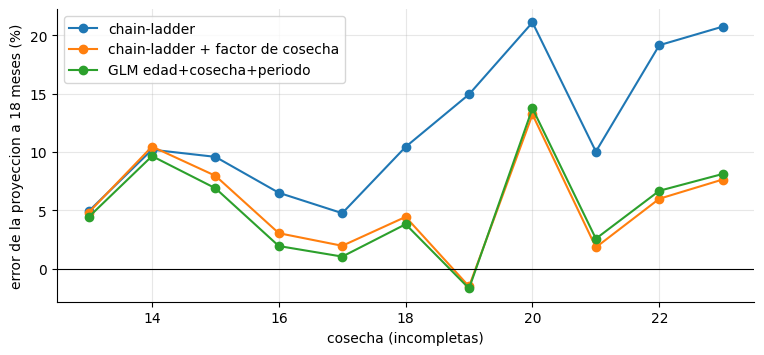

Lectura: error absoluto medio a 18 meses -> chain-ladder 12.0% | con factor de cosecha 5.7% | GLM 5.5%.
  Chain-ladder simple sobrestima en 11 de 11 cosechas (sesgo medio +12.0%).
  La diferencia entre 'con factor de cosecha' y el GLM es de 0.2 puntos: practicamente equivalentes; ambos mejoran claramente al chain-ladder simple.


In [12]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for c, lab in (("err_v2_sin_factor_%", "chain-ladder"), ("err_v2_con_factor_%", "chain-ladder + factor de cosecha"), ("err_v3_GLM_%", "GLM edad+cosecha+periodo")):
    ax.plot(res_proy.index, res_proy[c], "o-", label=lab)
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("cosecha (incompletas)"); ax.set_ylabel("error de la proyeccion a 18 meses (%)"); ax.legend(); plt.show()
ea = resumen["error_absoluto_medio_%"]
print(f"Lectura: error absoluto medio a {EDAD_OBJ} meses -> chain-ladder {ea['err_v2_sin_factor_%']:.1f}% | con factor de cosecha {ea['err_v2_con_factor_%']:.1f}% | GLM {ea['err_v3_GLM_%']:.1f}%.")
print(f"  Chain-ladder simple sobrestima en {int((res_proy['err_v2_sin_factor_%'] > 0).sum())} de {len(res_proy)} cosechas (sesgo medio {res_proy['err_v2_sin_factor_%'].mean():+.1f}%).")
dif = abs(ea['err_v2_con_factor_%'] - ea['err_v3_GLM_%'])
print(f"  La diferencia entre 'con factor de cosecha' y el GLM es de {dif:.1f} puntos: {'practicamente equivalentes' if dif < 1 else 'distintos'}; ambos mejoran claramente al chain-ladder simple.")

## 6. Robustez: ¿el resultado depende de la semilla?

In [13]:
def experimento(seed):
    rg = np.random.default_rng(seed)
    q = rg.lognormal(0, 0.10, V); q[8:11] *= 1.45
    filas = []
    for v in range(V):
        r_ = N
        for a in range(1, T_OBS - v + 1):
            d = rg.binomial(r_, H0 * sazon(a) * q[v] * macro(v + a)); filas.append((v, a, v + a, r_, d)); r_ -= d
    c = pd.DataFrame(filas, columns=["v", "a", "t", "riesgo", "d"])
    tot = c.groupby("v")["d"].sum() / N
    rho_ing = spearmanr(tot.values, q)[0]
    c["h_obs"] = c["d"] / c["riesgo"]
    a6 = pd.Series({v: 1 - np.prod(1 - c[(c.v == v) & (c.a <= 6)]["h_obs"]) for v in range(V)})
    rho_6 = spearmanr(a6.values, q)[0]
    Xa = pd.get_dummies(c["a"], prefix="a", drop_first=True).astype(float); Xv = pd.get_dummies(c["v"], prefix="v", drop_first=True).astype(float)
    Xt = pd.get_dummies(c["t"], prefix="t").astype(float); Z = np.column_stack([np.ones(len(c)), c["t"].to_numpy()])
    Xt_r = pd.DataFrame(Xt.to_numpy() - Z @ np.linalg.lstsq(Z, Xt.to_numpy(), rcond=None)[0], index=c.index, columns=Xt.columns)
    y = np.column_stack([c["d"], c["riesgo"] - c["d"]])
    res = {}
    for nombre, X in (("A", pd.concat([pd.Series(1.0, index=c.index, name="const"), Xa, Xv], axis=1)),
                      ("B", pd.concat([pd.Series(1.0, index=c.index, name="const"), Xa, Xv, Xt_r], axis=1))):
        m = sm.GLM(y, X.to_numpy(), family=sm.families.Binomial()).fit()
        co = pd.Series(m.params, index=X.columns)
        ev = np.array([0.0] + [co[f"v_{k}"] for k in range(1, V)])
        res[nombre] = np.corrcoef(sin_tendencia(ev), sin_tendencia(np.log(q) - np.log(q[0])))[0, 1]
    return rho_ing, rho_6, res["A"], res["B"]

rob = pd.DataFrame([experimento(s) for s in range(100, 112)], columns=["rho_a_la_fecha", "rho_a_6m", "corr_vintage_A", "corr_vintage_B"])
rob.describe().loc[["mean", "min", "max"]].round(3)

,rho_a_la_fecha,rho_a_6m,corr_vintage_A,corr_vintage_B
mean,0.5420,0.5840,0.9410,0.9580
min,0.2930,0.3540,0.8990,0.9100
max,0.7770,0.8360,0.9740,0.9820


In [14]:
print("Lectura (12 simulaciones):")
print(f"  Correlacion con la calidad verdadera: a la fecha {rob['rho_a_la_fecha'].mean():+.2f} | a 6 meses {rob['rho_a_6m'].mean():+.2f} | GLM sin periodo {rob['corr_vintage_A'].mean():+.2f} | GLM con periodo {rob['corr_vintage_B'].mean():+.2f}")
print(f"  El modelo con periodo gana al modelo sin periodo en {int((rob['corr_vintage_B'] > rob['corr_vintage_A']).sum())} de {len(rob)} simulaciones.")

Lectura (12 simulaciones):
  Correlacion con la calidad verdadera: a la fecha +0.54 | a 6 meses +0.58 | GLM sin periodo +0.94 | GLM con periodo +0.96
  El modelo con periodo gana al modelo sin periodo en 11 de 12 simulaciones.


## 7. Pruebas automáticas

In [15]:
# 7.1 los conteos se conservan: defaults + sobrevivientes = originados en cada cosecha y la censura es correcta
for v in range(V):
    c = celdas[celdas["v"] == v]
    assert c["riesgo"].iloc[0] == N
    assert (c["riesgo"].iloc[1:].to_numpy() == (c["riesgo"] - c["d"]).iloc[:-1].to_numpy()).all()
    assert c["a"].max() == T_OBS - v
# 7.2 el acumulado por producto de supervivencias coincide con defaults/originados cuando no hay otra salida
for v in (0, 5, 12):
    assert abs(acumulado(v, 6) - celdas[(celdas.v == v) & (celdas.a <= 6)]["d"].sum() / N) < 1e-9
# 7.3 la metrica 'a la fecha' esta dominada por la censura: mas correlacionada con los meses observados que con la calidad
assert abs(spearmanr(v1.values, edades_obs.values)[0]) > abs(rho_v1)
# 7.4 comparar a igual edad mejora el ranking de calidad frente a comparar a la fecha
assert rho6 > rho_v1 and rob["rho_a_6m"].mean() > rob["rho_a_la_fecha"].mean()
# 7.4b a igual edad, la exposicion macro explica nivel ademas de la calidad
assert ols.params["expo_macro_6m"] > 0 and ols.pvalues["expo_macro_6m"] < 0.01 and ols.params["log_calidad"] > 0
# 7.4c con factor de cosecha o con GLM la proyeccion es claramente mejor que el chain-ladder simple
assert resumen.loc["err_v2_con_factor_%", "error_absoluto_medio_%"] < 0.6 * resumen.loc["err_v2_sin_factor_%", "error_absoluto_medio_%"]
assert resumen.loc["err_v3_GLM_%", "error_absoluto_medio_%"] < 0.6 * resumen.loc["err_v2_sin_factor_%", "error_absoluto_medio_%"]
# 7.5 la franja de periodo se localiza cerca del pico verdadero (t=17)
assert abs(por_t.idxmax() - 17) <= 3
# 7.6 el modelo con periodo recupera mejor los efectos de cosecha y el efecto de periodo
assert res_ident.iloc[1, 0] > res_ident.iloc[0, 0] and res_ident.iloc[1, 1] < res_ident.iloc[0, 1]
assert corr_t > 0.8
assert (rob["corr_vintage_B"] > rob["corr_vintage_A"]).mean() >= 0.75
# 7.7 el modelo B ajusta mejor: la deviance cae y se acerca a los grados de libertad
assert mB.deviance < mA.deviance
# 7.8 las probabilidades predichas son validas y la proyeccion esta en [0,1] y no baja del acumulado observado
assert ((res_proy["v3_GLM"] > 0) & (res_proy["v3_GLM"] < 1)).all()
for v in incompletas:
    assert proyectar_glm(v) >= acumulado(v, int(edades_obs[v])) - 1e-12
# 7.9 la identificacion: sumar una tendencia lineal a los tres efectos no cambia las predicciones
k = 0.01
eta0 = XB.to_numpy() @ mB.params
a_, v_, t_ = celdas["a"].to_numpy(), celdas["v"].to_numpy(), celdas["t"].to_numpy()
eta1 = eta0 + k * a_ + k * v_ - k * t_                      # alfa + c*a, beta + c*v, gamma - c*t  =>  suma 0 porque t = v + a
assert np.allclose(eta0, eta1), "la tendencia lineal no esta identificada: debe dejar el ajuste intacto"
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| v1: acumulado a la fecha | Domina la censura: se relaciona más con los meses observados que con la calidad de la cosecha | No comparar cosechas con distinto tiempo de observación |
| v2: igual edad | El ranking mejora solo ligeramente; la exposición a la recesión explica parte del nivel a cada edad | Comparar a igual edad es necesario, no suficiente |
| Diagnóstico | El mapa edad × calendario muestra el choque como franja vertical alrededor del pico | Mirar siempre el calendario antes de culpar a la originación |
| v3: edad + cosecha + periodo | Mejora moderadamente la recuperación de la calidad (RMSE −33 %), recupera el choque (corr. 0,94) y deja la deviance cerca de sus grados de libertad | Fijar una convención explícita para la tendencia lineal |
| Proyección | El factor de cosecha y el GLM son equivalentes y recortan a la mitad el error del chain-ladder simple, que sobrestima sistemáticamente | Elegir por error fuera de muestra, no por elegancia |

**Límites que no deben ocultarse**

- El choque macro es una campana suave y conocida; uno real puede ser más abrupto o tener efectos distintos por segmento.
- El modelo asume que edad, cosecha y periodo actúan de forma aditiva en el logit; las interacciones (p. ej., la recesión pega más a cosechas jóvenes) no están modeladas.
- La proyección supone que el choque ya pasó (periodo neutro hacia adelante); en la práctica el escenario futuro es la parte incierta.
- Solo hay incumplimiento como salida: no se modelan prepagos ni otras salidas, que en una cartera real alteran la población en riesgo.
- Datos sintéticos: los porcentajes de error no son extrapolables.